# Fig. S5 — Plot

Draws Fig. S5 from the data in `data/`, produced by the notebooks in `notebooks/`. The panels are annotated in Inkscape into `figures/figS5.svg` / `figures/figS5.pdf`.

In [1]:
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import cm
from matplotlib.ticker import LogFormatterMathtext

In [2]:
class CustomLogFormatter(LogFormatterMathtext):
    def __call__(self, x, pos=None):
        if np.isclose(x, 1):
            return "1"
        elif np.isclose(x, 10):
            return "10"
        return super().__call__(x, pos)

In [3]:
mpl.rcParams.update({
    "font.family": "serif",
    "font.serif": ["cmr10"],
    "mathtext.fontset": "cm",
    "axes.unicode_minus": False,
    "axes.formatter.use_mathtext": True,
    "font.size": 12,          # general default
    "axes.labelsize": 12,   # X/Y labels
    "xtick.labelsize": 12,   # tick numbers
    "ytick.labelsize": 12,
    "legend.fontsize": 12,
    "axes.titlesize": 12    # optional
})

## Data

Spectra are stored as $10\log_{10}S$ in dB (negative = squeezing); rates and frequencies in 2π·GHz are converted to kHz / MHz.

In [4]:
kappa = np.load("data/kappa.npy")*1e6/(2*np.pi) # kHz
pos_eff = np.transpose(np.load("data/eff_positions.npy"))*1e3/(2*np.pi) # MHz
sq_spec = np.load("data/Ssq_full.npy")
sq_spec_eff = np.load("data/Ssq_eff.npy")
freqs = np.load("data/freqs.npy")*1e3/(2*np.pi) # MHz
equal = np.outer(np.load("data/kappa_ratio.npy"), np.ones(len(freqs))) # |κ/κ̃ - 1| on the (κ, ν) grid

X, Y = np.meshgrid(freqs,kappa)

## Plot

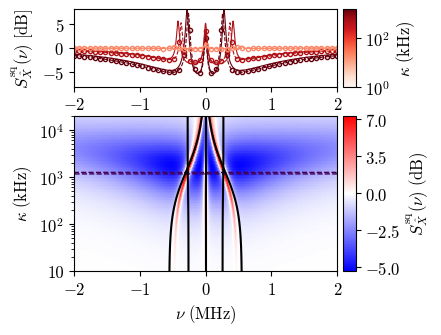

In [5]:
fig = plt.figure(figsize=(3.4,3.4))

# Axis layout

gs = fig.add_gridspec(2, 1, width_ratios=[1], height_ratios=[0.5,1], hspace=0.25, wspace=0.35)

ax_sqspec = fig.add_subplot(gs[1,0])
ax_cut = fig.add_subplot(gs[0,0])

# Squeezing spectrum

nrm = mpl.colors.TwoSlopeNorm(vmin=sq_spec.min(), vcenter=0, vmax=sq_spec.max())
cbar = plt.colorbar(cm.ScalarMappable(norm=nrm, cmap=cm.bwr), cax = ax_sqspec.inset_axes([1.02, 0.00, 0.05, 1.00]), orientation="vertical", location='right')
cbar.set_label(r'$S^\text{sq}_{\hat X}(\nu)\ (\text{dB})$', labelpad=3)
cbar.set_ticks([7, 3.5, 0, -2.5, -5])
ax_sqspec.pcolormesh(X, Y, sq_spec, cmap=cm.bwr, norm=nrm, rasterized=True)
ax_sqspec.contour(X, Y, equal, levels = [0.04], linewidths = 1, linestyles = 'dashed')

ax_sqspec.plot(pos_eff[1,:],kappa, color='black', markersize=2)
ax_sqspec.plot(pos_eff[0,:],kappa, color='black', markersize=2)
ax_sqspec.plot(-pos_eff[1,:],kappa, color='black', markersize=2)
ax_sqspec.plot(-pos_eff[0,:],kappa, color='black', markersize=2)
ax_sqspec.plot(pos_eff[2,:],kappa, color='black', markersize=2)

ax_sqspec.set_xlabel(r'$\nu\ (\text{MHz})$')
ax_sqspec.set_ylabel(r'$\kappa\ (\text{kHz})$')
ax_sqspec.set_ylim([kappa.min(),kappa.max()])
ax_sqspec.set_xlim([-2,2])
ax_sqspec.set_yscale('log')
ax_sqspec.set_xticks([-2,-1,0,1,2])
ax_sqspec.yaxis.set_major_formatter(CustomLogFormatter())
# ax_sqspec.xaxis.set_major_formatter(CustomLogFormatter())

# Spectrum cuts

# Top axis

ind_k = [65,50,9] # Cuts shown in the top axis (κ ≈ 1500, 450, 20 kHz)

cmap2 = plt.get_cmap('Reds')
nrm2 = mpl.colors.LogNorm(1,1500)

for i in range(3):
    ax_cut.plot(freqs,sq_spec[ind_k[i],:], color=cmap2(nrm2(kappa[ind_k[i]])), linewidth=0.8, linestyle='dashed')
    ax_cut.plot(freqs,sq_spec[ind_k[i],:], '.', fillstyle='none', markeredgewidth=1, color=cmap2(nrm2(kappa[ind_k[i]])), markevery=80, markersize=6)
    ax_cut.plot(freqs,sq_spec_eff[ind_k[i],:], color=cmap2(nrm2(kappa[ind_k[i]])), linewidth=0.8)

cbar_2 = plt.colorbar(cm.ScalarMappable(norm=nrm2, cmap=cmap2), cax = ax_cut.inset_axes([1.02, 0.00, 0.05, 1.00]), orientation="vertical", location='right')
cbar_2.set_label(r'$\kappa\ (\text{kHz})$', labelpad=3) 

ax_cut.set_ylabel(r'$S_{\hat X}^\text{sq}(\nu)\ \text{[dB]}$')
ax_cut.set_ylim([-8,8])
ax_cut.set_xlim([-2,2])

plt.savefig("figures/panels.svg", bbox_inches="tight")
plt.show()